In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

In [56]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,              # base font size
    'xtick.labelsize': 12,        # x-axis tick label size
    'ytick.labelsize': 12,        # y-axis tick label size
    'axes.labelsize': 12,         # axis label size
    'axes.titlesize': 12,         # title size
    'legend.fontsize': 12,        # legend font size
    'figure.titlesize': 12        # figure title size
})

In [3]:
df = pd.read_csv('../../testis-model-analysis/2025-drift-paper/all_clone_results.csv')
df.head()

,scenario,fish,clone,init_time,init_freq,last_time,max_time,max_freq,size,avg_freq_change,r_opt,if_opt,l_max,lower,upper,if_null,l_null
0,n500_r15_y6,0,0,1.0,0.304582,18.0,18.0,0.183288,0.289608,0.007135,21.919817,0.307162,-88.556002,8.503530,68.702417,0.289608,-251.078272
1,n500_r15_y6,0,1,1.0,0.156334,5.0,18.0,0.000000,0.023360,0.037062,24.455399,0.152912,-20.549349,5.447543,146.436829,0.023360,-249.564210
2,n500_r15_y6,0,2,1.0,0.115903,3.0,18.0,0.000000,0.015274,0.041779,47.988718,0.117011,-12.777606,7.574745,473.370544,0.015274,-208.366860
3,n500_r15_y6,0,3,1.0,0.094340,1.0,18.0,0.000000,0.005241,NaN,1000.000000,0.094286,-2.947001,20.938202,NaN,0.005241,-105.426060
4,n500_r15_y6,0,4,1.0,0.088949,2.0,18.0,0.000000,0.006439,0.061995,50.575174,0.088244,-7.588773,6.353441,NaN,0.006439,-107.163524


In [35]:
df2 = df.query('last_time > 1')

/opt/anaconda3/envs/tm/lib/python3.11/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


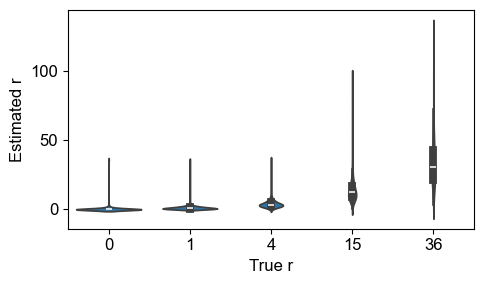

In [60]:
import seaborn as sns
import matplotlib.pyplot as plt
import re

# Define r values and corresponding scenario names
r_values = [0, 1, 4, 15, 36]
scenarios = [f'n1000_r{r}_y6' for r in r_values]

# Subset and extract r from scenario
df_plot = df2[df2['scenario'].isin(scenarios)].copy()
df_plot['true_r'] = df_plot['scenario'].str.extract(r'n1000_r(\d+)_y6').astype(int)
df_plot['log_r_opt'] = np.log(df_plot['r_opt'])

# Plot
plt.figure(figsize=(5, 3))
sns.violinplot(data=df_plot, x='true_r', y='r_opt', order=r_values, inner='box')
plt.xlabel("True r")
plt.ylabel("Estimated r")
plt.tight_layout()
plt.show()

In [62]:
for r in r_values:
    scenario = f'n1000_r{r}_y6'
    r_opts = df_plot.query(f'scenario == @scenario')['r_opt']
    print(f'r = {r}:\t{np.mean(r_opts):.2f}\t+/- {np.std(r_opts)/np.sqrt(len(r_opts)):.2f}')

r = 0:	0.40	+/- 0.08
r = 1:	1.25	+/- 0.05
r = 4:	4.20	+/- 0.11
r = 15:	14.47	+/- 0.33
r = 36:	34.85	+/- 0.79
